<a href="https://colab.research.google.com/github/shanmugasundaramkamaleswaran/AIML/blob/main/Stockprediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

In [ ]:
uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename, sep=None, engine="python")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Saving infolimpioavanzadoTarget.csv to infolimpioavanzadoTarget.csv
Dataset shape: (7781, 1285)
Columns: ['date', 'open', 'high', 'low', 'close', 'adjclose', 'volume', 'ticker', 'RSIadjclose15', 'RSIvolume15', 'RSIadjclose25', 'RSIvolume25', 'RSIadjclose50', 'RSIvolume50', 'MACDadjclose15', 'MACDvolume15', 'MACDadjclose25', 'MACDvolume25', 'MACDadjclose50', 'MACDvolume50', 'MACDsig-adjclose-15', 'MACDdif-adjclose-15-0', 'MACDdif-adjclose-15-1', 'MACDdif-adjclose-15-2', 'MACDdif-adjclose-15-3', 'MACDsig-volume-15', 'MACDdif-volume-15-0', 'MACDdif-volume-15-1', 'MACDdif-volume-15-2', 'MACDdif-volume-15-3', 'MACDsig-adjclose-25', 'MACDdif-adjclose-25-0', 'MACDdif-adjclose-25-1', 'MACDdif-adjclose-25-2', 'MACDdif-adjclose-25-3', 'MACDsig-volume-25', 'MACDdif-volume-25-0', 'MACDdif-volume-25-1', 'MACDdif-volume-25-2', 'MACDdif-volume-25-3', 'MACDsig-adjclose-50', 'MACDdif-adjclose-50-0', 'MACDdif-adjclose-50-1', 'MACDdif-adjclose-50-2', 'MACDdif-adjclose-50-3', 'MACDsig-volume-50', 'MACDdif

,date,open,high,low,close,adjclose,volume,ticker,RSIadjclose15,RSIvolume15,...,high-15,K-15,D-15,stochastic-k-15,stochastic-d-15,stochastic-kd-15,volumenrelativo,diff,INCREMENTO,TARGET
0,2022-01-03,17.799999,18.219000,17.500000,17.760000,17.760000,106600,ASLE,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.919758,-1.900001,-9.664295,0
1,2022-01-04,17.700001,18.309999,17.620001,17.660000,17.660000,128700,ASLE,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.110440,-1.379999,-7.247895,0
2,2022-01-05,17.580000,17.799999,16.910000,16.950001,16.950001,103100,ASLE,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.889560,-0.930000,-5.201344,0
3,2022-01-06,16.650000,16.879999,16.139999,16.170000,16.170000,173600,ASLE,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.497843,-0.360000,-2.177856,0
4,2022-01-07,16.219999,16.290001,15.630000,15.710000,15.710000,137800,ASLE,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.188956,-0.120000,-0.758054,0


In [ ]:
# Remove extra spaces
df.columns = df.columns.str.strip()

# Correct target column
target_col = "TARGET"

# Convert date and sort chronologically
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.dropna(subset=["date"])

# Sort by ticker and date
df = df.sort_values(["ticker", "date"])

# Select one stock for time-series training
selected_ticker = df["ticker"].mode()[0]
df = df[df["ticker"] == selected_ticker].copy()

print("Selected ticker:", selected_ticker)

# Remove non-numeric columns
df = df.drop(columns=["date", "ticker"])

# Replace invalid values
df = df.replace([np.inf, -np.inf], np.nan)

# Convert numerical columns
df = df.apply(pd.to_numeric, errors="coerce")

# Remove columns containing only missing values
df = df.dropna(axis=1, how="all")

# Fill missing values using past observations
df = df.ffill().dropna()

# Move target column to last position
feature_cols = [c for c in df.columns if c != target_col]
df = df[feature_cols + [target_col]]

print("Final dataset shape:", df.shape)
print("Target values:", df["TARGET"].unique()[:20])

Selected ticker: ASLE
Final dataset shape: (153, 1283)
Target values: [0 1]


In [ ]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

target_col = "TARGET"

# Identify target type
classes = np.sort(df[target_col].dropna().unique())
is_classification = (
    len(classes) <= 20 and
    np.all(np.isclose(classes, np.round(classes)))
)

# Separate features and target
X_data = df.drop(columns=[target_col])
y_data = df[target_col].values

# 80% training, 20% testing
train_size = int(len(df) * 0.8)

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_data.iloc[:train_size])
X_test_scaled = scaler.transform(X_data.iloc[train_size:])

X_scaled = np.vstack([X_train_scaled, X_test_scaled])

if is_classification:
    from sklearn.preprocessing import LabelEncoder
    encoder = LabelEncoder()
    y_data = encoder.fit_transform(y_data)

print("Classification:", is_classification)
print("Training rows:", train_size)
print("Testing rows:", len(df) - train_size)

Classification: True
Training rows: 122
Testing rows: 31


In [ ]:
time_steps = 10

def create_sequences(X, y, steps):
    X_seq, y_seq = [], []

    for i in range(steps, len(X)):
        X_seq.append(X[i-steps:i])
        y_seq.append(y[i])

    return np.array(X_seq), np.array(y_seq)

X, y = create_sequences(X_scaled, y_data, time_steps)

split = train_size - time_steps

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (112, 10, 1282)
Testing shape: (31, 10, 1282)


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

model = Sequential([
    Input(shape=(time_steps, X_train.shape[2])),
    LSTM(64),
    Dropout(0.2),
    Dense(32, activation="relu")
])

if is_classification:
    n_classes = len(np.unique(y_data))

    if n_classes == 2:
        model.add(Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    else:
        model.add(Dense(n_classes, activation="softmax"))
        loss = "sparse_categorical_crossentropy"

    metrics = ["accuracy"]

else:
    model.add(Dense(1))
    loss = "mse"
    metrics = ["mae"]

model.compile(
    optimizer="adam",
    loss=loss,
    metrics=metrics
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 64)             │       344,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 346,945 (1.32 MB)

 Trainable params: 346,945 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 209ms/step - accuracy: 0.5300 - loss: 0.6984 - val_accuracy: 1.0000 - val_loss: 0.3447
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.6700 - loss: 0.6739 - val_accuracy: 1.0000 - val_loss: 0.2241
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.6700 - loss: 0.7033 - val_accuracy: 1.0000 - val_loss: 0.2386
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.6700 - loss: 0.6705 - val_accuracy: 1.0000 - val_loss: 0.2847
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step - accuracy: 0.6700 - loss: 0.6650 - val_accuracy: 1.0000 - val_loss: 0.3132
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.6700 - loss: 0.6425 - val_accuracy: 1.0000 - val_loss: 0.3183
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.6700 - loss: 0.6370 - val_accuracy: 1.0000 - val_loss: 0.3116
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.6700 - loss: 0.6392 - val_accuracy: 1.0000 - val_loss: 0.3033

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pred = model.predict(X_test)

if is_classification:

    if n_classes == 2:
        y_pred = (pred.flatten() >= 0.5).astype(int)
    else:
        y_pred = np.argmax(pred, axis=1)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

else:
    y_pred = pred.flatten()

    print("MAE:", mean_absolute_error(y_test, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
    print("R2 Score:", r2_score(y_test, y_pred))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 555ms/step
Accuracy: 0.9032258064516129

Classification Report:
              precision    recall  f1-score   support

           0       0.90      1.00      0.95        28
           1       0.00      0.00      0.00         3

    accuracy                           0.90        31
   macro avg       0.45      0.50      0.47        31
weighted avg       0.82      0.90      0.86        31



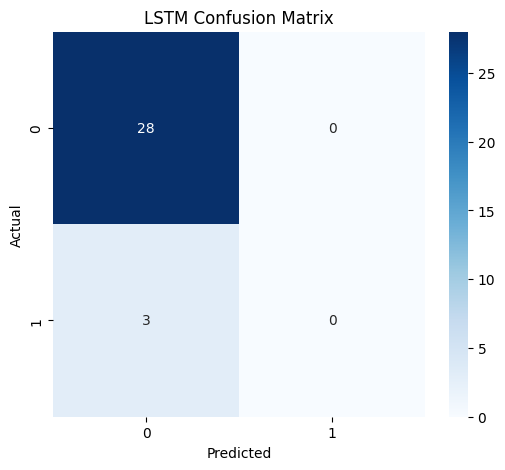

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

plt.figure(figsize=(12, 5))
plt.plot(y_test, label="Actual Price")
plt.plot(y_pred, label="Predicted Price")
plt.title("Google Stock Price Prediction using LSTM")
plt.xlabel("Days")
plt.ylabel("Stock Price")
plt.legend()
plt.show()

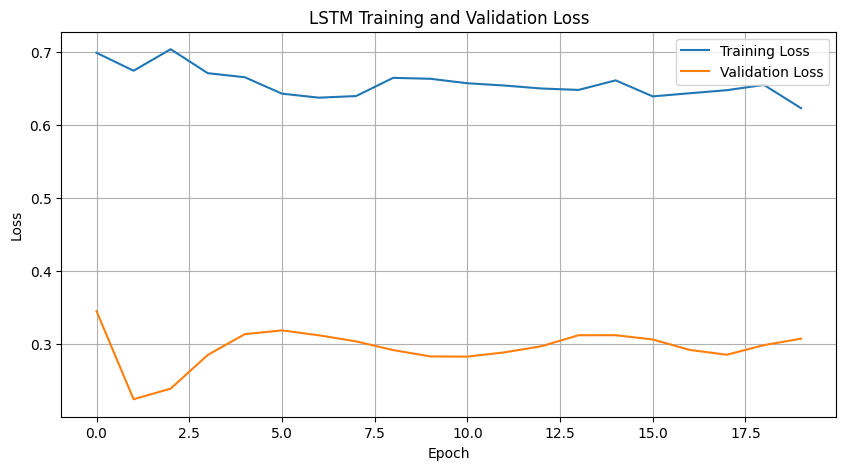

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()